## Loading Dataset
see some lines of the Dataset 

In [89]:
import pandas as pd 
df = pd.read_csv("vm_cpu_readings.csv")
df.head()

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [90]:
print(df.columns.tolist())

['timestamp', 'vm_id', 'min_cpu', 'max_cpu', 'avg_cpu']


In [91]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 1340000 entries, 0 to 1339999
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   timestamp  1340000 non-null  int64  
 1   vm_id      1340000 non-null  str    
 2   min_cpu    1340000 non-null  float64
 3   max_cpu    1340000 non-null  float64
 4   avg_cpu    1340000 non-null  float64
dtypes: float64(3), int64(1), str(1)
memory usage: 132.9 MB


(1340000, 5)

In [92]:
print(df.describe())

          timestamp       min_cpu       max_cpu       avg_cpu
count  1.340000e+06  1.340000e+06  1.340000e+06  1.340000e+06
mean   1.995000e+04  6.156478e+00  1.834830e+01  9.388101e+00
std    1.160442e+04  1.175525e+01  2.161651e+01  1.426601e+01
min    0.000000e+00  0.000000e+00  1.810795e-02  7.158922e-03
25%    9.900000e+03  1.487979e+00  4.417642e+00  2.477060e+00
50%    1.995000e+04  3.227996e+00  9.124204e+00  5.105133e+00
75%    3.000000e+04  5.331087e+00  2.362418e+01  9.616715e+00
max    3.990000e+04  9.928158e+01  9.970286e+01  9.948803e+01


# Show the None and Nll Value

In [93]:
print("----None---- \n")
missing_value = df.isna().sum()
print(missing_value)
print("\n---- Null----\n")
print(df.isnull().sum())

----None---- 

timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64

---- Null----

timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64


In [94]:
print("Duplicate rows: ",df.duplicated().sum())

Duplicate rows:  0


### Distribution of Average CPU

This histogram shows the distribution of average CPU utilization across the virtual machines. It helps identify common CPU usage ranges, the spread of values, and potential skewness in the data.

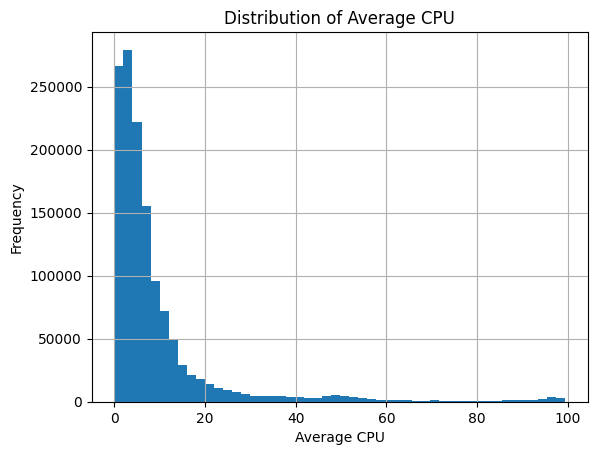

In [95]:
import matplotlib.pyplot as plt

df["avg_cpu"].hist(bins=50)

plt.title("Distribution of Average CPU")
plt.xlabel("Average CPU")
plt.ylabel("Frequency")

plt.show()

### CPU Utilization Over Time for One VM

This line plot shows how the average CPU utilization of a single virtual machine changes over time. It helps identify workload patterns, fluctuations, and periods of high or low CPU usage.

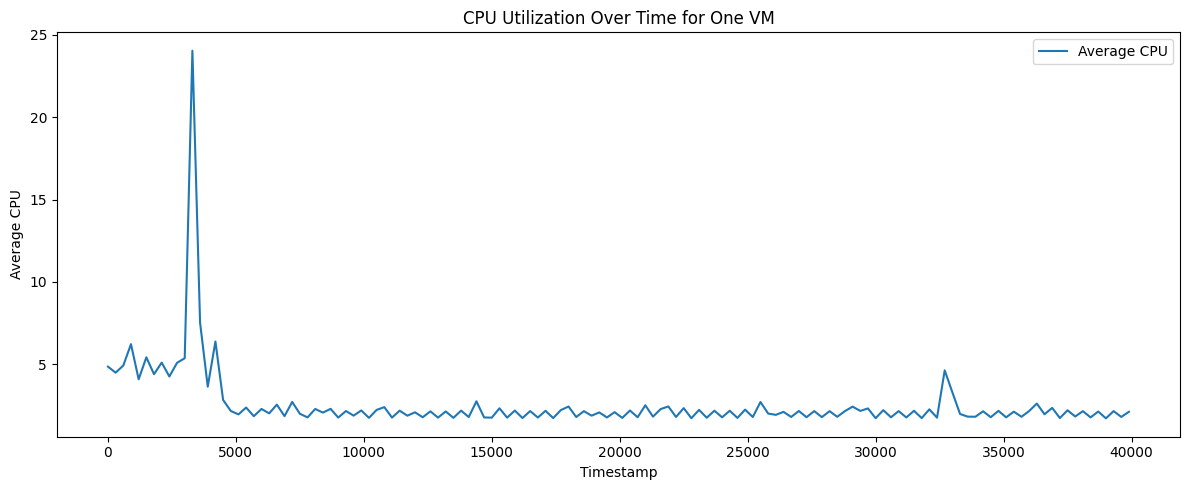

In [96]:
vm_id = df["vm_id"].iloc[0]

vm_df = df[df["vm_id"] == vm_id].copy()
vm_df = vm_df.sort_values("timestamp")

plt.figure(figsize=(12, 5))

plt.plot(
    vm_df["timestamp"],
    vm_df["avg_cpu"],
    label="Average CPU"
)

plt.title("CPU Utilization Over Time for One VM")
plt.xlabel("Timestamp")
plt.ylabel("Average CPU")
plt.legend()
plt.tight_layout()
plt.show()

### CPU Feature Correlation Matrix

This heatmap shows the correlations between `min_cpu`, `max_cpu`, and `avg_cpu`. It helps identify the strength and direction of linear relationships between CPU features and determine how closely these measurements are related.

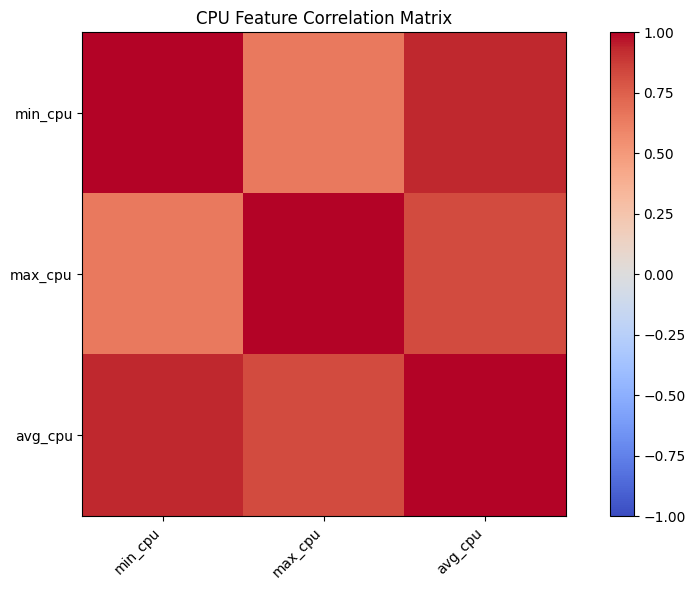

In [97]:
# Select numeric CPU features
numeric_columns = ["min_cpu", "max_cpu", "avg_cpu"]

# Calculate correlation
correlation = df[numeric_columns].corr()

# Plot correlation matrix
plt.figure(figsize=(9, 6))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.colorbar()
plt.title("CPU Feature Correlation Matrix")
plt.tight_layout()
plt.show()

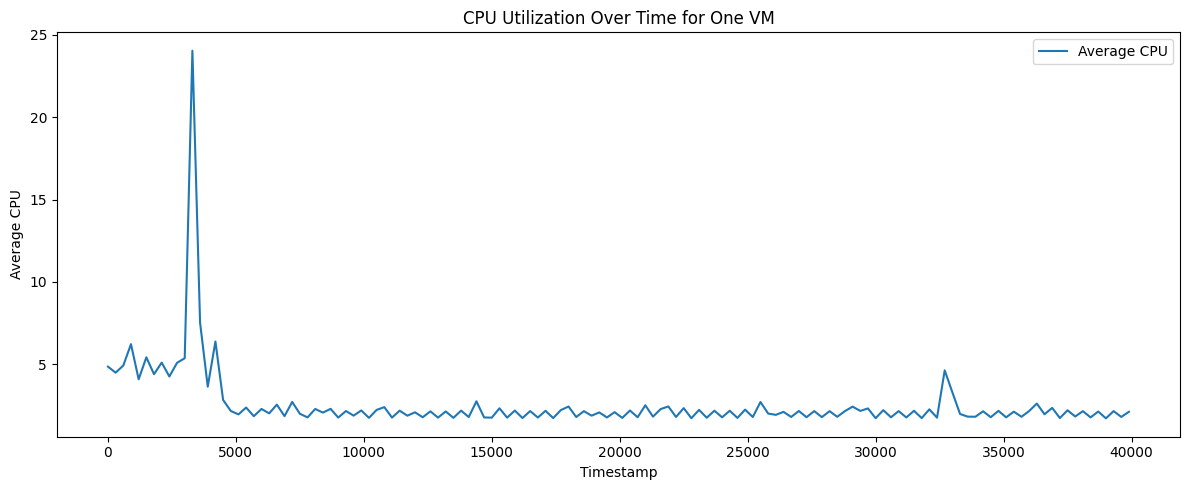

In [98]:
vm_id = df["vm_id"].iloc[0]

vm_df = df[df["vm_id"] == vm_id].copy()
vm_df = vm_df.sort_values("timestamp")

plt.figure(figsize=(12, 5))

plt.plot(
    vm_df["timestamp"],
    vm_df["avg_cpu"],
    label="Average CPU"
)

plt.title("CPU Utilization Over Time for One VM")
plt.xlabel("Timestamp")
plt.ylabel("Average CPU")
plt.legend()
plt.tight_layout()
plt.show()

### CPU Features Boxplot

This boxplot compares the distributions of `min_cpu`, `max_cpu`, and `avg_cpu`. It helps identify the spread of CPU utilization, the median values, and potential outliers in the data.

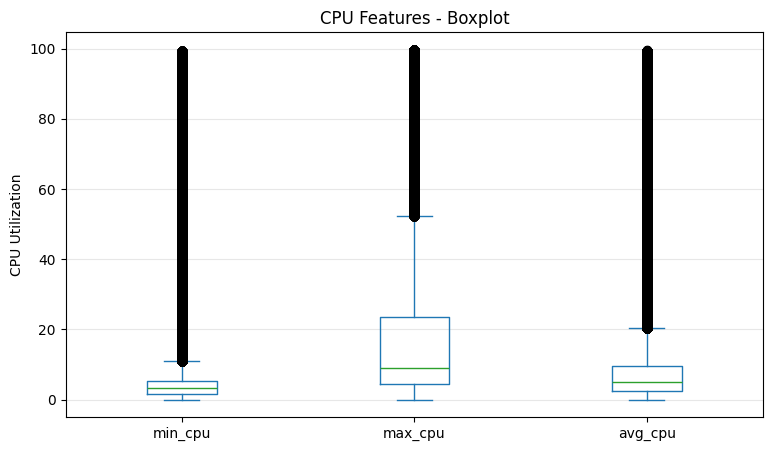

In [99]:
import matplotlib.pyplot as plt

df[["min_cpu", "max_cpu", "avg_cpu"]].plot(
    kind="box",
    figsize=(9, 5)
)

plt.title("CPU Features - Boxplot")
plt.ylabel("CPU Utilization")
plt.grid(axis="y", alpha=0.3)
plt.show()

### Target Variable Construction

This step aggregates VM-level CPU readings by timestamp to create the two target variables required for forecasting: `active_vm_count`, representing the number of unique VMs recorded at each timestamp, and `aggregate_cpu_utilization`, representing the mean CPU utilization across VMs. The resulting dataset is sorted chronologically and checked to verify its structure.

In [101]:
targets = (
    df.groupby("timestamp")
      .agg(
          active_vm_count=("vm_id", "nunique"),
          aggregate_cpu_utilization=("avg_cpu", "mean")
      )
      .reset_index()
      .sort_values("timestamp")
      .reset_index(drop=True)
)

print(targets.head())
print(targets.shape)

   timestamp  active_vm_count  aggregate_cpu_utilization
0          0            10000                   9.396898
1        300            10000                   9.353775
2        600            10000                   9.454383
3        900            10000                   9.224419
4       1200            10000                   9.143503
(134, 3)


### Aggregate CPU Utilization Over Time

This line plot visualizes the average CPU utilization across all virtual machines at each timestamp. It helps identify temporal trends, fluctuations, and periods of high or low CPU usage.

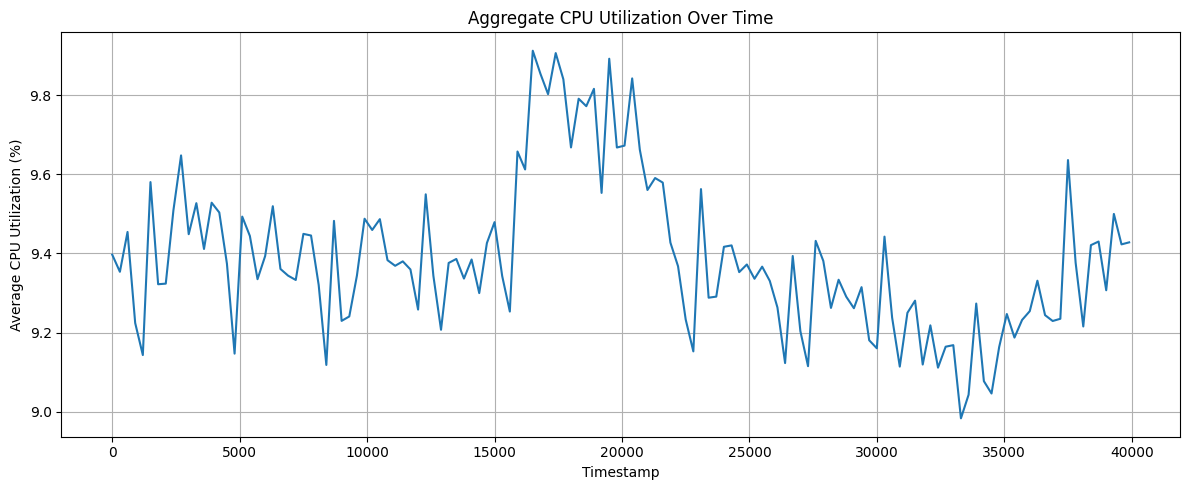

In [102]:
plt.figure(figsize=(12, 5))
plt.plot(
    targets["timestamp"],
    targets["aggregate_cpu_utilization"]
)

plt.title("Aggregate CPU Utilization Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Average CPU Utilization (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

### Active VM Count Over Time

This line plot shows how the number of active virtual machines changes over time. It helps identify changes in VM activity and determine whether the workload size remains stable or varies across timestamps.

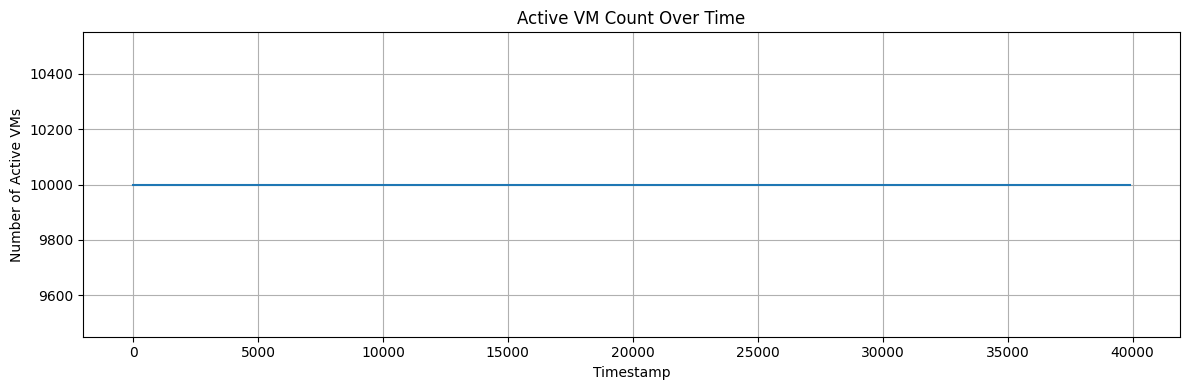

In [103]:
plt.figure(figsize=(12, 4))
plt.plot(targets["timestamp"], targets["active_vm_count"])

plt.title("Active VM Count Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Number of Active VMs")
plt.grid(True)
plt.tight_layout()
plt.show()